# $\sqrt{5}\log\varphi$: historical CMF bounds

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    hata_pfq_seeds, source_residue_depths,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, y0 = sp.symbols('x0 x1 y0')


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Hata (1992): $\sqrt{5}\log\varphi$

[Theorem 1.1, Theorem 3.1 and Eq. (3.10)](https://matwbn.icm.edu.pl/ksiazki/aa/aa60/aa6043.pdf).

**CMF:** ${}_2F_1(1/s)$, rank 2. Parameters $(d,s,\lambda,c)$ are given in the cell.
**Start:** $(2,2-d;4-d)$. **Direction:** $(\lambda,\lambda;2\lambda+1)$.
**Readout:** $-c(CW)_0/(BW)_0$, with exact coefficient rows transported from $(1,1-d;2-d)$.

Only source indices N = 1 + λk occur. The last admissible index below 500 is 499, shown explicitly in the table.

In [5]:
d, s, lam, scale = (sp.Rational('1/2'), 5, 2, sp.Rational('1'))
cmf = pFq(2, 1, sp.Rational(1, s))
start = {x0: 2, x1: 2 - d, y0: 4 - d}
trajectory = {x0: lam, x1: lam, y0: 2 * lam + 1}
C, B = hata_pfq_seeds(cmf, d, s, start)
depths = source_residue_depths(DEPTHS, 1, lam)
walks = cmf.walk(trajectory, [(N - 1) // lam for N in depths], start)
approximants = [-scale * (C * W)[0] / (B * W)[0] for W in walks]
target = lambda: arb(5).sqrt() * ((1 + arb(5).sqrt()) / 2).log()

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['$\\sqrt{5}\\log\\varphi$'] = (depths, deltas)
accuracy['$\\sqrt{5}\\log\\varphi$'] = [value[1] for value in measurements]
print(f"delta at N = {depths[-1]}: {deltas[-1]:.12f}")

delta at N = 499: 0.283427034952


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

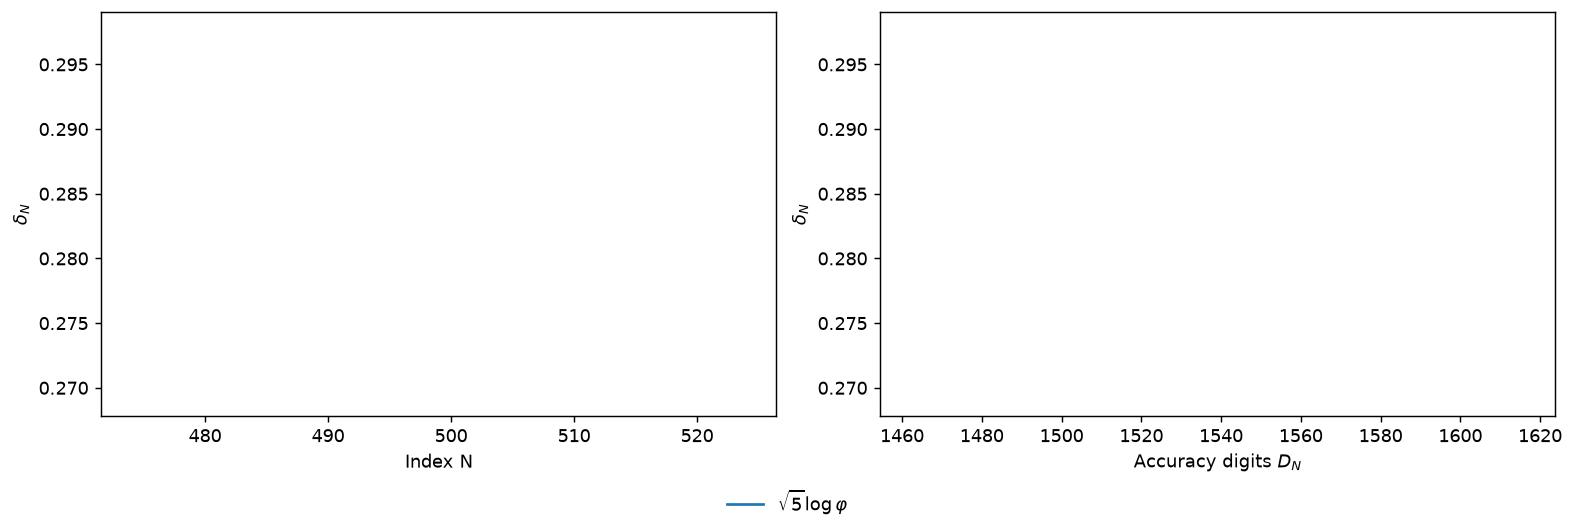

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [9]:
bounds = {
    '$\\sqrt{5}\\log\\varphi$': '4.4937113...',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| $\sqrt{5}\log\varphi$ | 4.4937113... | 0.283427034952 (N = 499) |